# Tarea raster · 4. ¿A quién alcanza el fuego? Personas y viviendas en Livitaca y Huanoquite

Reto D aplicado a los dos incendios del Cusco. Dos fuentes que miden cosas distintas:

| Fuente | Qué mide | Tipo |
|---|---|---|
| **WorldPop 2020** | Personas *estimadas* por celda de ~1 km (modelo que reparte el censo) | Raster |
| **Google Open Buildings v3** | Edificaciones *detectadas* en imágenes satelitales de 50 cm | Puntos (uno por techo) |

Compararlas es en sí un hallazgo: ¿el modelo de población "ve" a la gente que vive dispersa en la
puna, donde sí se ven sus casas?

**Zonas de distancia** (franjas alrededor del borde del área quemada **amplia**, dNBR ≥ 0,10). Las
distancias son **decisiones nuestras**, elegidas según lo que cada una permite leer:

| Zona | Qué significa |
|---|---|
| Dentro del área quemada | El fuego pasó por ahí: **exposición directa** |
| Hasta 100 m | El fuego llegó "a la puerta": **exposición directa** (un píxel de 20 m mezcla el techo con el pasto de al lado) |
| Hasta 500 m | **Riesgo directo**: poblados que el fuego pudo alcanzar si seguía avanzando |
| Hasta 1 km | **Impacto en el medio de vida**: familias cuyos pastos de uso diario se quemaron |

**Por qué no 5 km aquí.** El radio de 5 km del notebook 2 es una convención del monitor del
profesor para "población cercana" y se mide desde los focos VIIRS. Aquí medimos desde el área
quemada de Sentinel-2: mezclar ambos daría números que parecen comparables y no lo son. Livitaca
y Huanoquite aparecen en el ranking nacional de 5 km del notebook 2, calculados igual que el resto.

**Exposición no es daño.** El satélite no puede decir si una casa se quemó: una casa de adobe y
calamina puede tener el fuego al lado sin arder. Para daños hay que ir a INDECI o a la prensa local.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterstats import zonal_stats

from comun import RAW, PROC, FIG, CRS_METRICO

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

In [2]:
quemado = gpd.read_file(PROC / "area_quemada_cusco.gpkg").to_crs(CRS_METRICO)
amplia = quemado[quemado.cifra == "amplia"].set_index("incendio").geometry

ZONAS = {"dentro del área quemada": 0, "hasta 100 m": 100, "hasta 500 m": 500, "hasta 1 km": 1000}
zonas = gpd.GeoDataFrame(
    [{"incendio": inc, "zona": z, "geometry": geom.buffer(m) if m else geom}
     for inc, geom in amplia.items() for z, m in ZONAS.items()], crs=CRS_METRICO)
zonas["km2"] = zonas.area / 1e6
zonas[["incendio", "zona", "km2"]].round(1)

,incendio,zona,km2
0,Livitaca,dentro del área quemada,9.3
1,Livitaca,hasta 100 m,13.5
2,Livitaca,hasta 500 m,23.8
3,Livitaca,hasta 1 km,37.1
4,Huanoquite,dentro del área quemada,8.9
5,Huanoquite,hasta 100 m,14.8
6,Huanoquite,hasta 500 m,28.2
7,Huanoquite,hasta 1 km,41.3


## Personas: WorldPop

**Problema de escala.** El área quemada de cada incendio mide 9 km² o menos, y una celda de WorldPop
mide ~1 km². Con `zonal_stats` directo, una celda entra entera o no entra según su centro.

**Decisión:** dividir cada celda de 1 km en 10 × 10 sub-celdas de ~100 m, repartiendo su población
en partes iguales (`sum` se conserva). Así una zona que toca media celda recibe media población. Es
un supuesto de reparto uniforme dentro de la celda, no información nueva.

In [3]:
caja = zonas.to_crs(4326).total_bounds
with rasterio.open(RAW / "worldpop_per_2020_1km.tif") as src:
    ventana = rasterio.windows.from_bounds(*caja, transform=src.transform).round_offsets().round_lengths()
    ventana = rasterio.windows.Window(ventana.col_off - 1, ventana.row_off - 1, ventana.width + 3, ventana.height + 3)
    pob = src.read(1, window=ventana, masked=True).filled(0)
    t = src.window_transform(ventana)
    total_original = pob.sum()
    fino = np.repeat(np.repeat(pob, 10, axis=0), 10, axis=1) / 100
    t_fino = t * t.scale(1 / 10)
print(f"población en la ventana: {total_original:,.0f} (1 km) = {fino.sum():,.0f} (100 m): se conserva")

zonas_4326 = zonas.to_crs(4326)
zonas["personas"] = [z["sum"] or 0 for z in zonal_stats(list(zonas_4326.geometry), fino, affine=t_fino,
                                                         stats=["sum"], nodata=-1)]

población en la ventana: 108,084 (1 km) = 108,084 (100 m): se conserva


## Viviendas: Open Buildings

Leemos solo la caja de los dos incendios (+ 4 km) del bloque `917` (~96 MB comprimido), por partes
para no cargar millones de filas en memoria.

Dos decisiones:

1. **Confianza ≥ 0,75.** El archivo trae edificaciones desde 0,65. Google recomienda umbrales más
   altos donde importan los falsos positivos; en la puna, rocas y corrales de piedra pueden
   confundirse con techos. Mostramos también el conteo con 0,65 para ver la sensibilidad.
2. **Edificaciones, no hogares.** Un punto es un techo: puede ser vivienda, cocina, depósito o
   capilla. En la sierra rural una familia suele tener varias construcciones. Por eso hablamos de
   "edificaciones" y no convertimos a personas.

In [4]:
cajab = zonas.buffer(3000).to_crs(4326).total_bounds              # margen para el mapa de contexto
partes = []
for trozo in pd.read_csv(RAW / "open_buildings_v3_points_917.csv.gz", chunksize=2_000_000,
                         usecols=["latitude", "longitude", "area_in_meters", "confidence"]):
    partes.append(trozo[trozo.longitude.between(cajab[0], cajab[2]) & trozo.latitude.between(cajab[1], cajab[3])])
edif = pd.concat(partes, ignore_index=True)
edif = gpd.GeoDataFrame(edif, geometry=gpd.points_from_xy(edif.longitude, edif.latitude), crs=4326).to_crs(CRS_METRICO)
print(f"edificaciones en la caja: {len(edif):,} (confianza ≥ 0,65)  ·  {(edif.confidence >= 0.75).sum():,} con ≥ 0,75")
print(edif.area_in_meters.describe(percentiles=[.25, .5, .75]).round(0).to_string())

edificaciones en la caja: 196,048 (confianza ≥ 0,65)  ·  131,373 con ≥ 0,75
count    196048.0
mean         48.0
std          62.0
min           3.0
25%          22.0
50%          35.0
75%          55.0
max        5279.0


In [5]:
unidas = gpd.sjoin(edif, zonas[["incendio", "zona", "geometry"]], predicate="within")
conteo = unidas.groupby(["incendio", "zona"]).agg(
    edif_065=("confidence", "size"),
    edif_075=("confidence", lambda c: (c >= 0.75).sum()),
    area_mediana_m2=("area_in_meters", "median"))
zonas = zonas.merge(conteo, on=["incendio", "zona"], how="left").fillna({"edif_065": 0, "edif_075": 0})

## Resultado

In [6]:
zonas["personas_por_edif"] = zonas.personas / zonas.edif_075.replace(0, np.nan)
tabla = (zonas.set_index(["incendio", "zona"])
         [["km2", "personas", "edif_075", "edif_065", "area_mediana_m2", "personas_por_edif"]]
         .rename(columns={"km2": "km²", "personas": "personas (WorldPop)", "edif_075": "edificaciones (conf ≥ 0,75)",
                          "edif_065": "edificaciones (conf ≥ 0,65)", "area_mediana_m2": "techo mediano (m²)",
                          "personas_por_edif": "personas por edificación"}))
tabla.to_csv(PROC / "personas_viviendas_cusco.csv")
tabla.round(1)

km²  personas (WorldPop)  \
incendio   zona                                                 
Livitaca   dentro del área quemada   9.3                100.9   
           hasta 100 m              13.5                145.0   
           hasta 500 m              23.8                259.3   
           hasta 1 km               37.1                413.6   
Huanoquite dentro del área quemada   8.9                 79.5   
           hasta 100 m              14.8                132.0   
           hasta 500 m              28.2                260.6   
           hasta 1 km               41.3                393.0   

                                    edificaciones (conf ≥ 0,75)  \
incendio   zona                                                   
Livitaca   dentro del área quemada                            2   
           hasta 100 m                                       13   
           hasta 500 m                                      100   
           hasta 1 km                                       216   
Huanoquite dentro del área quemada                            2   
           hasta 100 m                                        4   
           hasta 500 m                                      122   
           hasta 1 km                                       171   

                                    edificaciones (conf ≥ 0,65)  \
incendio   zona                                                   
Livitaca   dentro del área quemada                            4   
           hasta 100 m                                       23   
           hasta 500 m                                      209   
           hasta 1 km                                       418   
Huanoquite dentro del área quemada                            3   
           hasta 100 m                                        6   
           hasta 500 m                                      169   
           hasta 1 km                                       247   

                                    techo mediano (m²)  \
incendio   zona                                          
Livitaca   dentro del área quemada                16.2   
           hasta 100 m                            18.4   
           hasta 500 m                            21.3   
           hasta 1 km                             24.0   
Huanoquite dentro del área quemada                31.6   
           hasta 100 m                            50.9   
           hasta 500 m                            32.7   
           hasta 1 km                             33.4   

                                    personas por edificación  
incendio   zona                                               
Livitaca   dentro del área quemada                      50.4  
           hasta 100 m                                  11.2  
           hasta 500 m                                   2.6  
           hasta 1 km                                    1.9  
Huanoquite dentro del área quemada                      39.8  
           hasta 100 m                                  33.0  
           hasta 500 m                                   2.1  
           hasta 1 km                                    2.3

### Mapa

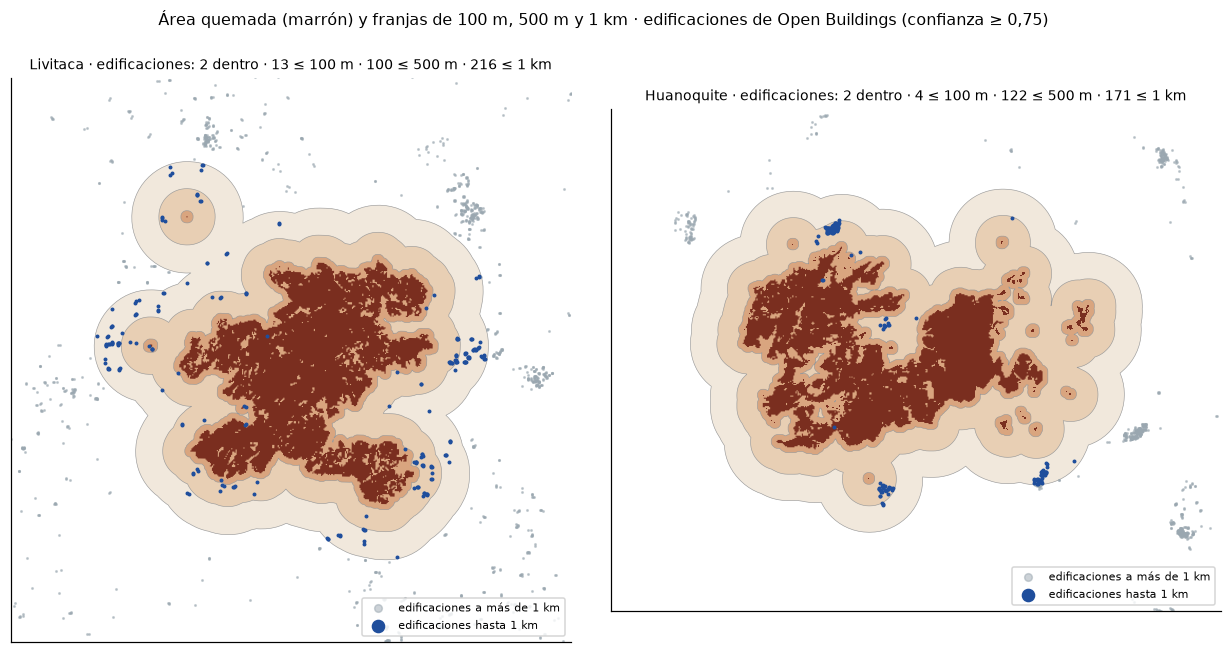

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 6))
fuertes = edif[edif.confidence >= 0.75]
for ax, (inc, geom) in zip(ejes, amplia.items()):
    z = zonas[zonas.incendio == inc].set_index("zona")
    lim = z.loc["hasta 1 km"].geometry.buffer(1500).bounds
    for zona, color in (("hasta 1 km", "#f1e8dc"), ("hasta 500 m", "#e8cfb4"), ("hasta 100 m", "#d9a57f")):
        gpd.GeoSeries([z.loc[zona].geometry], crs=CRS_METRICO).plot(ax=ax, color=color, edgecolor="#999", linewidth=0.4)
    gpd.GeoSeries([geom], crs=CRS_METRICO).plot(ax=ax, color="#7a2e1f", linewidth=0)
    dentro_1km = fuertes.within(z.loc["hasta 1 km"].geometry)
    ax.scatter(fuertes[~dentro_1km].geometry.x, fuertes[~dentro_1km].geometry.y, s=1, c="#9aa7b0", alpha=0.5,
               label="edificaciones a más de 1 km")
    ax.scatter(fuertes[dentro_1km].geometry.x, fuertes[dentro_1km].geometry.y, s=2.5, c="#1f4e9c",
               label="edificaciones hasta 1 km")
    ax.set_title(f"{inc} · edificaciones: {z.loc['dentro del área quemada'].edif_075:,.0f} dentro · "
                 f"{z.loc['hasta 100 m'].edif_075:,.0f} ≤ 100 m · {z.loc['hasta 500 m'].edif_075:,.0f} ≤ 500 m · "
                 f"{z.loc['hasta 1 km'].edif_075:,.0f} ≤ 1 km", fontsize=9)
    ax.set_xlim(lim[0], lim[2]); ax.set_ylim(lim[1], lim[3]); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc="lower right", fontsize=7.5, markerscale=5)
fig.suptitle("Área quemada (marrón) y franjas de 100 m, 500 m y 1 km · edificaciones de Open Buildings (confianza ≥ 0,75)",
             fontsize=10.5)
plt.tight_layout(rect=[0, 0, 1, 0.95]); fig.savefig(FIG / "04_personas_viviendas.png", dpi=150); plt.show()

## Lectura

1. **El fuego quemó pastos y llegó a la puerta de pocas casas.** Dentro del área quemada hay 2
   edificaciones por incendio. A ≤ 100 m: **13 en Livitaca** y 4 en Huanoquite (exposición directa).
2. **Riesgo directo a ≤ 500 m:** 100 edificaciones en Livitaca y **122 en Huanoquite**. En Huanoquite
   el salto entre 100 m (4) y 500 m (122) muestra que el fuego se detuvo a pocos cientos de metros de
   dos poblados (al norte y al sur del área quemada).
3. **Dos patrones de asentamiento.** En Livitaca (Chumbivilcas) las edificaciones están **dispersas**
   alrededor de todo el borde: estancias familiares junto a sus pastos. Por eso más casas quedan
   pegadas al fuego (13 a ≤ 100 m). En Huanoquite (Paruro) están **agrupadas** en núcleos: casi
   ninguna toca el fuego, pero cuando el fuego se acerca a un núcleo, expone a muchas a la vez.
4. **Medio de vida a ≤ 1 km:** 216 edificaciones en Livitaca y 171 en Huanoquite pertenecen a familias
   cuyos pastos cercanos se quemaron en plena época seca.
5. **WorldPop no sirve a esta escala.** Pone ~100 y ~80 personas dentro del área quemada, donde casi
   no hay techos: la versión *unconstrained* reparte población en toda la celda de 1 km, incluso en
   pasto vacío. Para un incendio, las edificaciones de Open Buildings dicen más que WorldPop.

**Sensibilidad:** con confianza ≥ 0,65 las cifras suben (Livitaca ≤ 100 m: 23; ≤ 500 m: 209), pero
el patrón no cambia.